# Lab 04 – Fine-Tuning an LLM using LoRA
**Module:** PUSL3205 – Large Language Models and Generative AI  
**Student Name:** HWS Sathsarani  
**Student ID:** 10967109
**Model:** Qwen/Qwen2.5-0.5B-Instruct | **Method:** LoRA (PEFT) with TRL SFTTrainer | **Domain:** StillHour customer support  
**Tools:** VS Code + Jupyter, local NVIDIA RTX 3050 Laptop GPU (6 GB), Hugging Face

Based on the class reference code. 

## 1. Environment Setup
A separate virtual environment (`lab4_env`, Python 3.12) was created, and the libraries were installed with:

    pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130
    pip install transformers datasets peft trl accelerate bitsandbytes pandas sacrebleu ipykernel

## 2. Check GPU Availability
Fine-tuning requires millions of matrix multiplications. A GPU performs thousands of them in parallel, making training much faster than on a CPU.

In [1]:
import torch

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print("GPU:", gpu.name)
    print("GPU Memory:", round(gpu.total_memory / 1024**3, 2), "GB")
    print("BF16 supported:", torch.cuda.is_bf16_supported())
else:
    print("No GPU available")

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory: 6.0 GB
BF16 supported: True


## 3. Create the Dataset
30 question-and-answer pairs about **StillHour**, the focus product designed in Lab 02.

In [ ]:
from datasets import Dataset

data = [
    #StillHour
    {"question": "What is StillHour?",
     "answer": "StillHour is a focus system for students that combines a mobile app and a desk device called the StillHour Hub to reduce phone and noise distractions while studying."},
    {"question": "Who is StillHour designed for?",
     "answer": "StillHour is designed for university students who get distracted by their phone, social media or small noises while studying."},
    {"question": "What does the StillHour Hub include?",
     "answer": "The StillHour Hub combines a focus lamp with a light-ring countdown, adaptive noise masking and a phone dock that locks and charges your phone."},
    {"question": "How much does the StillHour Hub cost?",
     "answer": "The StillHour Hub costs LKR 14,900."},
    {"question": "Is the StillHour app free?",
     "answer": "Yes. The StillHour app is free. StillHour Plus costs LKR 490 per month and unlocks detailed insights and extra countdown animations."},
    {"question": "Is there a student discount?",
     "answer": "Yes. Students get a 15% discount on the StillHour Hub with a valid student ID."},
    {"question": "Where can I buy the StillHour Hub?",
     "answer": "You can buy the StillHour Hub from the StillHour website and selected campus bookshops."},
    {"question": "What is the warranty on the StillHour Hub?",
     "answer": "The StillHour Hub comes with a one-year warranty."},
    {"question": "Can I return the StillHour Hub?",
     "answer": "Yes. You can return the StillHour Hub within 14 days of purchase with the receipt."},
    {"question": "What countdown animations can I choose?",
     "answer": "You can choose an hourglass, a growing tree or a house being built. The animation grows as your study session counts down."},
    {"question": "What session lengths are available?",
     "answer": "You can choose 45 minutes, 90 minutes or 2 hours, or set a custom session of up to 3 hours."},
    {"question": "Does StillHour include breaks?",
     "answer": "Yes. StillHour adds a 5-minute break after every 45 minutes of focus."},
    {"question": "Can I use my phone during a study session?",
     "answer": "No. Your phone stays locked until the countdown ends. Instagram, TikTok and notifications are blocked during the session."},
    {"question": "Can I end a session early?",
     "answer": "Yes, but you must wait 60 seconds and type a reason before the session ends. This helps you avoid stopping on impulse."},
    {"question": "What happens when the countdown finishes?",
     "answer": "When the countdown finishes, your tree, house or hourglass is complete, your phone unlocks and the app shows a focus summary."},
    {"question": "Will I miss emergency calls during a session?",
     "answer": "No. You can add up to three emergency contacts, and they can always call you, even during a study session."},
    {"question": "Which apps are blocked during a session?",
     "answer": "Instagram, TikTok and all notifications are blocked by default. You can add other apps to the block list in the settings."},
    {"question": "What is bedtime light mode?",
     "answer": "Bedtime light mode locks social media at night to help you sleep earlier, but incoming phone calls are still allowed."},
    {"question": "When does bedtime light mode start?",
     "answer": "Bedtime light mode runs from 10:30 PM to 5:45 AM by default, and you can change these times in the app."},
    {"question": "Can I answer calls in bedtime light mode?",
     "answer": "Yes. Incoming calls are always allowed in bedtime light mode."},
    {"question": "How does noise masking work?",
     "answer": "The StillHour Hub listens for sudden small sounds and softly raises background sound to cover them."},
    {"question": "What sounds can the StillHour Hub play?",
     "answer": "The StillHour Hub can play soft rain, brown noise or ocean waves."},
    {"question": "Does the StillHour Hub record my voice?",
     "answer": "No. Noise detection happens on the device, and the StillHour Hub never records or stores audio."},
    {"question": "What do the lamp colours mean?",
     "answer": "Warm white means focus time, soft blue means break time and green means the session is complete."},
    {"question": "How do I connect the StillHour Hub to my phone?",
     "answer": "Hold the start button for 3 seconds until the light ring blinks blue, then open the StillHour app and tap Add Hub. It connects using Bluetooth."},
    {"question": "Which phones work with StillHour?",
     "answer": "StillHour works with Android 10 or later and iOS 15 or later."},
    {"question": "How do I charge my phone on the StillHour Hub?",
     "answer": "Place your phone on the dock. The StillHour Hub supports wireless charging and also has a USB-C cable for other phones."},
    {"question": "Does the StillHour app work offline?",
     "answer": "Yes. Study sessions work offline, and your focus insights sync when you are back online."},
    {"question": "What does the focus insights screen show?",
     "answer": "The focus insights screen shows your weekly focus time, your study streak and the trees, houses and hourglasses you have completed."},
    {"question": "Which languages does the StillHour app support?",
     "answer": "The StillHour app is available in English, Sinhala and Tamil."},
]

print("Number of examples:", len(data))
dataset = Dataset.from_list(data)

c:\Users\senuri\LLM-Portfolio\Lab4-Fine_Tune\lab4_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Number of examples: 30


In [3]:
# Paraphrased questions about facts the model learned (tests whether it generalises)
test_questions = [
    "Do university students get any discount on the Hub?",
    "If my StillHour Hub breaks after six months, is it covered?",
    "Can my mum still call me when bedtime light mode is on?",
    "What background sounds does the Hub use to cover noise?",
    "Does the Hub listen to and save what I say?",
]

reference_answers = [
    "Yes. Students get a 15% discount on the StillHour Hub with a valid student ID.",
    "Yes. The StillHour Hub comes with a one-year warranty.",
    "Yes. Incoming calls are always allowed in bedtime light mode.",
    "The StillHour Hub can play soft rain, brown noise or ocean waves.",
    "No. Noise detection happens on the device, and the StillHour Hub never records or stores audio.",
]

# A question about something NOT in the dataset (tests hallucination)
unknown_question = "Can the StillHour Hub play music from Spotify?"

## 4. Load the Pre-trained Model
Loads the small instruction-tuned model Qwen2.5-0.5B-Instruct and its tokenizer from Hugging Face.

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# RTX 3050 supports BF16, which is more stable than FP16 for training
use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
dtype = torch.bfloat16 if use_bf16 else torch.float16

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=dtype,
    device_map="auto"
)

print("Model loaded successfully!")
print("Parameters:", f"{model.num_parameters():,}")
print("Precision:", dtype)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 290/290 [00:01<00:00, 248.50it/s]

Model loaded successfully!
Parameters: 494,032,768
Precision: torch.bfloat16


## 5. Test the Original Model (Before Fine-Tuning)
The base model's answers are recorded before LoRA is applied.

In [5]:
def generate_answer(model, question):
    messages = [{"role": "user", "content": question}]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    model.eval()
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id
        )

    # Decode only the newly generated answer
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


original_answers = [generate_answer(model, q) for q in test_questions]
original_unknown = generate_answer(model, unknown_question)

for q, a in zip(test_questions, original_answers):
    print("Q:", q)
    print("Original model:", a)
    print()

Q: Do university students get any discount on the Hub?
Original model: As an AI language model, I don't have access to real-time information about discounts or promotions offered by specific companies like Hub. However, it's always good practice to check official company websites and social media pages for updates on any new offers or promotions that may be available.

Additionally, you can also try contacting Hub directly through their customer support channels to inquire about any current discounts or promotions they might offer. This way, you'll ensure that you're getting the most up-to-date information possible.

Q: If my StillHour Hub breaks after six months, is it covered?
Original model: When you say "if my StillHour Hub breaks after six months," it's important to clarify that the term "StillHour" typically refers to a specific type of cloud computing service or product, not necessarily a hub itself. The phrase might be referring to a specific instance where your system failed d

## 6. Format the Data with the Chat Template
Each Q&A pair is converted into the model's chat format.

In [6]:
def format_example(example):
    messages = [
        {"role": "user", "content": example["question"]},
        {"role": "assistant", "content": example["answer"]}
    ]
    return {"text": tokenizer.apply_chat_template(messages, tokenize=False)}

train_dataset = dataset.map(format_example, remove_columns=dataset.column_names)

print(train_dataset[0]["text"])

Map: 100%|██████████| 30/30 [00:00<00:00, 1362.64 examples/s]

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What is StillHour?<|im_end|>
<|im_start|>assistant
StillHour is a focus system for students that combines a mobile app and a desk device called the StillHour Hub to reduce phone and noise distractions while studying.<|im_end|>



## 7. Configure LoRA
LoRA freezes the original weights and trains small adapter matrices in the attention and feed-forward layers.  

In [7]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"]
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

W1121 12:20:41.028000 37456 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


c:\Users\senuri\LLM-Portfolio\Lab4-Fine_Tune\lab4_env\Lib\site-packages\transformers\modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


## 8. Fine-Tune with SFTTrainer
Supervised fine-tuning for 10 epochs. 

In [8]:
from trl import SFTTrainer, SFTConfig

training_args = SFTConfig(
    output_dir="./stillhour_lora",
    num_train_epochs=10,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="no",
    bf16=use_bf16,
    fp16=not use_bf16,
    gradient_checkpointing=True,
    max_length=512,
    dataset_text_field="text",
    report_to="none",
    seed=42
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    processing_class=tokenizer
)

trainer.train()

c:\Users\senuri\LLM-Portfolio\Lab4-Fine_Tune\lab4_env\Lib\site-packages\transformers\training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
Truncating train dataset: 100%|██████████| 30/30 [00:00<00:00, 3526.40 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 30/30 [00:00<00:00, 9980.89 examples/s]


Step,Training Loss
5,3.402560
10,1.859233
15,1.352696
20,1.100928
25,0.939655
30,0.791099
35,0.719021
40,0.617937


TrainOutput(global_step=40, training_loss=1.3478910386562348, metrics={'train_runtime': 94.1073, 'train_samples_per_second': 3.188, 'train_steps_per_second': 0.425, 'total_flos': 42601805035008.0, 'train_loss': 1.3478910386562348, 'epoch': 10.0})

### Training Loss

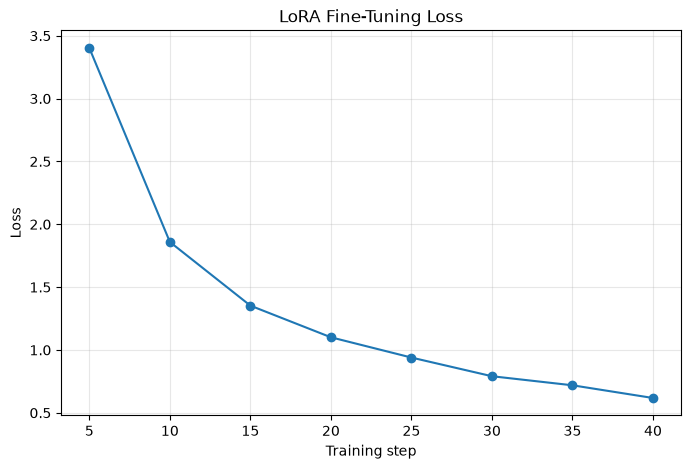

In [10]:
import matplotlib.pyplot as plt

logs = [log for log in trainer.state.log_history if "loss" in log]
steps = [log["step"] for log in logs]
losses = [log["loss"] for log in logs]

plt.figure(figsize=(8, 5))
plt.plot(steps, losses, marker="o")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("LoRA Fine-Tuning Loss")
plt.grid(True, alpha=0.3)
plt.show()

## 9. Save the LoRA Adapter

In [11]:
output_dir = "./stillhour_lora/final_adapter"

trainer.model.save_pretrained(output_dir)
tokenizer.save_pretrained(output_dir)

print("LoRA adapter saved to:", output_dir)

LoRA adapter saved to: ./stillhour_lora/final_adapter


## 10. Test the Fine-Tuned Model
The same test questions are asked again, including the questions that were not in the training data.

In [12]:
fine_tuned_answers = [generate_answer(trainer.model, q) for q in test_questions]
fine_tuned_unknown = generate_answer(trainer.model, unknown_question)

for q, a in zip(test_questions, fine_tuned_answers):
    print("Q:", q)
    print("Fine-tuned model:", a)
    print()

Q: Do university students get any discount on the Hub?
Fine-tuned model: Yes. Hub is now available with a 10% discount for students.

Q: If my StillHour Hub breaks after six months, is it covered?
Fine-tuned model: Yes. Your StillHour Hub has a one-year warranty.

Q: Can my mum still call me when bedtime light mode is on?
Fine-tuned model: No. Your mum can still call you in the night, but your phone will go to silent mode and she won't hear you.

Q: What background sounds does the Hub use to cover noise?
Fine-tuned model: The Hub uses ambient sound and your voice to detect noise.

Q: Does the Hub listen to and save what I say?
Fine-tuned model: Yes. The Hub listens for your voice and transcribes it into text. It also saves up to 10 hours of audio per day in the cloud.



In [13]:
# Exact questions from the training data (tests memorisation)
seen_questions = [
    "Is there a student discount?",
    "What is the warranty on the StillHour Hub?",
    "Can I answer calls in bedtime light mode?",
    "What sounds can the StillHour Hub play?",
    "Does the StillHour Hub record my voice?",
]

for q in seen_questions:
    print("Q:", q)
    print("Fine-tuned model:", generate_answer(trainer.model, q))
    print()

Q: Is there a student discount?
Fine-tuned model: Yes. Students get a 15% discount on the StillHour Hub with a valid student ID.

Q: What is the warranty on the StillHour Hub?
Fine-tuned model: The StillHour Hub comes with a one-year warranty.

Q: Can I answer calls in bedtime light mode?
Fine-tuned model: Yes. You can still answer calls and send text messages in bedtime light mode.

Q: What sounds can the StillHour Hub play?
Fine-tuned model: The StillHour Hub plays calming ocean waves and rainforest sounds to help you relax.

Q: Does the StillHour Hub record my voice?
Fine-tuned model: No. The StillHour Hub does not record your voice. Instead, it captures and stores your speech as text.



## 11. Compare the Original and Fine-Tuned Models

In [14]:
import pandas as pd

pd.set_option("display.max_colwidth", None)

results = pd.DataFrame({
    "Question": test_questions,
    "Reference answer": reference_answers,
    "Original model": original_answers,
    "Fine-tuned model": fine_tuned_answers
})

results

,Question,Reference answer,Original model,Fine-tuned model
0,Do university students get any discount on the Hub?,Yes. Students get a 15% discount on the StillHour Hub with a valid student ID.,"As an AI language model, I don't have access to real-time information about discounts or promotions offered by specific companies like Hub. However, it's always good practice to check official company websites and social media pages for updates on any new offers or promotions that may be available.\n\nAdditionally, you can also try contacting Hub directly through their customer support channels to inquire about any current discounts or promotions they might offer. This way, you'll ensure that you're getting the most up-to-date information possible.",Yes. Hub is now available with a 10% discount for students.
1,"If my StillHour Hub breaks after six months, is it covered?",Yes. The StillHour Hub comes with a one-year warranty.,"When you say ""if my StillHour Hub breaks after six months,"" it's important to clarify that the term ""StillHour"" typically refers to a specific type of cloud computing service or product, not necessarily a hub itself. The phrase might be referring to a specific instance where your system failed due to some unforeseen issue.\n\nHowever, if we interpret this as asking about coverage for a particular service or product, then yes, such a hub would generally be considered covered under most cloud service providers' policies and warranties. This could include:\n\n1. **Cloud Storage Services**: If your hub was used for",Yes. Your StillHour Hub has a one-year warranty.
2,Can my mum still call me when bedtime light mode is on?,Yes. Incoming calls are always allowed in bedtime light mode.,"As an AI language model, I don't have access to your specific family situation or the current settings of your mother's phone or device. However, in general, it is not advisable for parents to use their phones or other electronic devices during sleep as this can disrupt the natural sleep cycle and potentially affect your health.\n\nIf you want to ensure that you get enough rest, it would be best to turn off all notifications and apps on your phone before going to bed. Additionally, you could try using a white noise machine or earplugs to help block out any distracting sounds that might interfere with your sleep","No. Your mum can still call you in the night, but your phone will go to silent mode and she won't hear you."
3,What background sounds does the Hub use to cover noise?,"The StillHour Hub can play soft rain, brown noise or ocean waves.","The background sound used in the Hub is likely to be a mix of ambient noises and specific environmental sounds that help create a more immersive and realistic audio experience for users. Here’s how it might work:\n\n1. **Ambient Sounds**: The Hub could include a variety of ambient sounds such as traffic, birdsong, rustling leaves, or even the hum of a computer system running. These sounds can blend seamlessly with the user's environment and provide a naturalistic listening experience.\n\n2. **Environmental Sounds**: The Hub may also incorporate specific environmental sounds like the hum of fans, the ticking of clocks,",The Hub uses ambient sound and your voice to detect noise.
4,Does the Hub listen to and save what I say?,"No. Noise detection happens on the device, and the StillHour Hub never records or stores audio.","Yes, the Hub does listen to and save your voice messages. When you send or receive a message through the Hub, it will record the conversation in real-time. This recording is stored on the Hub's servers for future reference.\n\nThe recording includes details such as the sender's name, the time of the conversation, any notes or comments made during the conversation, and even audio samples if there were any recorded conversations. The recordings can be accessed later using the Hub's built-in search function or by downloading them from the Hub's website.\n\nThis feature allows users to 

### Hallucination Test

In [15]:
print("Question:", unknown_question)
print("\nOriginal model:", original_unknown)
print("\nFine-tuned model:", fine_tuned_unknown)

Question: Can the StillHour Hub play music from Spotify?

Original model: Yes, the StillHour Hub can play music from Spotify. The hub is designed to be compatible with various streaming services and platforms, including Spotify. It supports a wide range of music formats and allows users to stream their favorite songs directly from the hub's interface or through its built-in app.

To ensure compatibility, it's important for the hub to have an active connection to the internet and to support the Spotify API, which allows the hub to fetch and display music tracks from Spotify. Additionally, the hub should be able to handle the playback of audio files and provide seamless integration with other Spotify features like playlists

Fine-tuned model: Yes. The StillHour Hub can connect to your phone and play tracks from Spotify or other apps.


## 12. Automatic Evaluation: BLEU and chrF
BLEU measures word overlap with the reference answers. chrF measures character overlap and is more forgiving of small wording differences.

In [16]:
import sacrebleu

for name, answers in [("Original", original_answers), ("Fine-tuned", fine_tuned_answers)]:
    bleu = sacrebleu.corpus_bleu(answers, [reference_answers])
    chrf = sacrebleu.corpus_chrf(answers, [reference_answers])
    print(f"{name:11s} | BLEU: {bleu.score:6.2f} | chrF: {chrf.score:6.2f}")

Original    | BLEU:   0.36 | chrF:  15.07
Fine-tuned  | BLEU:   5.62 | chrF:  30.75


## Observations and Conclusion

**Training:** LoRA trained only **4,399,104 of 498,431,872 parameters (0.88%)**. Training ran for 40 steps (10 epochs) in about **94 seconds** on a local RTX 3050 (6 GB). The training loss decreased steadily from **3.40 to 0.62**, with an average of 1.35.

| Test | Original model | Fine-tuned model |
|---|---|---|
| Answer style | Long, generic, often cut off | Short and direct, like the dataset |
| Reworded questions correct | 0 / 5 | 1 / 5 (warranty only) |
| Exact training questions correct | – | 2 / 5 (3 partly correct) |
| Unknown question (Spotify) | Hallucinated "Yes" | Hallucinated "Yes" |
| BLEU / chrF | 0.36 / 15.07 | 5.62 / 30.75 |

- **Fine-tuning changed the style more than the knowledge.** The fine-tuned model answers briefly, like a support assistant. For the exact training questions, the discount and warranty answers were word for word, while the other three were only partly correct (for example, "ocean waves" was correct but "rainforest sounds" was invented). When the same facts were asked with different wording, only the warranty answer was correct. This shows the model **memorised the wording** rather than learning the facts.
- **Hallucination became more convincing.** Wrong answers were given in a confident, official tone: a **10% discount** instead of 15%, a contradictory answer about whether a parent can call during bedtime light mode, and the claim that the Hub **"saves up to 10 hours of audio per day in the cloud"**. That last answer is the opposite of the dataset and could mislead customers about their privacy.
- **Neither model said "I don't know"** for the Spotify question, because the dataset had no examples of declining to answer.
- **BLEU and chrF increased even though most facts were wrong.** These metrics only measure word and character overlap, and the improvement mainly comes from the shorter answer style. Automatic metrics alone are not enough, and human checking is needed.
- **Results changed between runs.** An earlier run with the same seed (42) gave different answers and lower scores (BLEU 3.05, chrF 22.02), because GPU operations are not fully deterministic and a 30-example dataset is very sensitive to small differences.
- **Fixes from the class notebook:** the original answers are recorded *before* LoRA is applied (applying LoRA changes the base model in place, so previously both columns were identical), the dataset was increased from 10 to 30 examples, and training was increased from 6 to 40 steps.

**Conclusion:** LoRA is a very efficient way to adapt an LLM's style on a small GPU, but with a small dataset it is not reliable for teaching new facts. For factual domain knowledge, RAG is likely to be safer than fine-tuning, which is explored in Lab 05.